# Word2Vec from Scratch (CBOW + Skip-gram) — Paper Implementation Project
**Course:** Deep Learning 2026  |  **Paper:** Mikolov, Chen, Corrado, Dean — *Efficient Estimation of Word Representations in Vector Space* (arXiv:1301.3781)  
**Student:** Sudipto Ghosh | **Roll no.:** 24CS2037 | **Paper ID:** DL-041 (Beginner, Classic)

### How to use this notebook (Google Colab, free T4)
1. `Runtime → Change runtime type → T4 GPU`.
2. Run cells **top to bottom**. Every long experiment is cached in `results_quick.json` / `results_full.json`, so if Colab disconnects you can re-run and finished runs are skipped.
3. Set `QUICK = True` in Section 1 first (≈10 min total) to verify everything works, then switch to `QUICK = False` for the final numbers.

### What is implemented (own code) vs. reused
| Component | Source |
|---|---|
| CBOW and Skip-gram models, training loop, batching, subsampling, negative sampler, evaluation code | **Written by me in PyTorch (this notebook)** |
| `nn.Embedding`, `SparseAdam`, `torch.multinomial`, t-SNE (scikit-learn) | Standard building blocks |
| `gensim` | **Used only** as (i) a source of the WordSim-353 file and (ii) an *optional external reference run* for sanity-checking my numbers (Section 9). Not used in my models. |

### Documented deviations from the paper (stated honestly, see report)
| Paper | Here | Why |
|---|---|---|
| Hierarchical softmax (Huffman tree) | **Negative sampling** (Mikolov et al., NIPS 2013, ref. [21] of the paper; the paper itself says it is the follow-up work) | Simpler on GPU, brief asks for negative sampling |
| Google News 6B tokens, DistBelief, 50-100 CPU replicas | text8 (17M tokens), 1 GPU | Compute limit (free Colab T4) |
| Adagrad / plain SGD, lr 0.025 linearly → 0 | **SparseAdam**, lr linearly → ~0 | Mini-batched GPU training makes plain SGD unstable for frequent words (see Section 4 note) |
| Evaluate on full 19,544 questions | Same questions, **restricted to words in my vocabulary; coverage always reported** | text8 is much smaller than Google News |

In [1]:
# ===== 0. Setup =====
!pip -q install gensim scikit-learn 2>&1 | tail -1
# If the next import line fails with a numpy/scipy "binary incompatibility" error: Runtime > Restart session, then run again.
import os, time, math, json, random, zipfile, urllib.request, collections
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)
if device == "cpu":
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU (CPU will be ~20x slower).")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | torch 2.11.0+cu130


## 1. Global configuration
All hyper-parameters live in one dictionary `BASE`. Every ablation changes **one factor at a time** relative to `BASE`; nothing else is touched. This is what makes the ablations interpretable.

| Key | Meaning | Paper reference |
|---|---|---|
| `arch` | `"skipgram"` or `"cbow"` | Sec. 3.1, 3.2 |
| `dim` | embedding size D | Table 2 (50-600), Table 3 (640) |
| `C` | maximum window; actual window `R ~ Uniform{1..C}` per centre word | Sec. 3.2 (C=10 in the paper) |
| `K` | negative samples per positive pair | NIPS'13 [21] (not in this paper) |
| `t` | subsampling threshold of frequent words (0 = off) | NIPS'13 [21] |
| `epochs` | passes over data | paper: 3 for Table 2/4, 1 for later |
| `lr` | initial learning rate, decayed linearly to ~0 | paper: 0.025 (SGD) |
| `B` | centre positions per mini-batch | — |
| `frac` | fraction of text8 used (data-size study) | Table 2 |

In [2]:
QUICK = False        # True: 1 epoch, 1 seed, fewer grid points (smoke test). False: final numbers.

BASE = dict(arch="skipgram", dim=100, C=5, K=5, t=1e-4, epochs=1 if QUICK else 3,
            lr=3e-3, B=1024, min_count=5, frac=1.0, seed=0)
SEEDS      = [0] if QUICK else [0, 1, 2]       # repeats for the main comparison (mean +- std)
VOCAB_EVAL = 30000                              # eval search space = 30k most frequent words (paper Sec. 4.2)
RESULTS_FILE = "results_quick.json" if QUICK else "results_full.json"   # separate files: quick and final runs never mix
def emb_path(arch): return f"emb_{arch}_{'quick' if QUICK else 'full'}.pt"   # embeddings of seed SEEDS[0]
print(BASE, SEEDS)

{'arch': 'skipgram', 'dim': 100, 'C': 5, 'K': 5, 't': 0.0001, 'epochs': 3, 'lr': 0.003, 'B': 1024, 'min_count': 5, 'frac': 1.0, 'seed': 0} [0, 1, 2]


## 2. Data: text8, vocabulary, unigram statistics
`text8` = first 100 MB of an English Wikipedia dump, cleaned to lowercase letters only (≈17.0 M tokens).

*Design decisions*  
- Words with count < `min_count` (5) are dropped from the stream (as in the original C code); this fixes the vocabulary V.  
- Vocabulary is sorted by frequency, so **index = frequency rank**. This lets us restrict evaluation to the top-30k words by slicing `E[:30000]`, exactly the protocol of the paper's Table 2.

In [3]:
def fetch(url, fn):
    # download with a browser-like User-Agent (some hosts answer 403 to python-urllib)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as r, open(fn, "wb") as f:
        f.write(r.read())
    return fn

def load_text8():
    if not os.path.exists("text8"):
        try:
            fetch("http://mattmahoney.net/dc/text8.zip", "text8.zip")
            zipfile.ZipFile("text8.zip").extractall(".")
        except Exception as e:                       # fallback mirror through gensim
            print("direct download failed (", e, ") -> gensim mirror")
            if os.path.exists("text8.zip"): os.remove("text8.zip")
            import gensim.downloader as api
            toks = [w for sent in api.load("text8") for w in sent]
            open("text8", "w").write(" ".join(toks))
    return open("text8").read().split()

tokens = load_text8()
print(f"{len(tokens):,} tokens, e.g. {tokens[:12]}")

def build_vocab(tokens, min_count):
    cnt = collections.Counter(tokens)
    items = sorted([(w, c) for w, c in cnt.items() if c >= min_count], key=lambda x: -x[1])
    itos = [w for w, _ in items]
    stoi = {w: i for i, w in enumerate(itos)}
    counts = np.array([c for _, c in items], dtype=np.int64)
    ids = np.fromiter((stoi[w] for w in tokens if w in stoi), dtype=np.int64)
    return itos, stoi, counts, ids

itos, stoi, counts, ids_full = build_vocab(tokens, BASE["min_count"])
V = len(itos)
print(f"V = {V:,} words, kept {len(ids_full):,} / {len(tokens):,} tokens")
print("top-10:", itos[:10])

17,005,207 tokens, e.g. ['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against', 'early', 'working']
V = 71,290 words, kept 16,718,844 / 17,005,207 tokens
top-10: ['the', 'of', 'and', 'one', 'in', 'a', 'to', 'zero', 'nine', 'two']


## 3. Evaluation (written first, so that no model choice can be influenced by results)

**Analogy task (paper Sec. 4.1).** For a question `a : b :: c : ?` compute `x = vec(b) − vec(a) + vec(c)` and return the word with the highest **cosine** similarity to `x`, excluding `a, b, c`. Correct only on *exact match* (synonyms count as errors). Questions come from the official `questions-words.txt` (5 semantic + 9 syntactic types, 19,544 questions).

**Similarity task.** Spearman ρ between cosine similarity and human scores on WordSim-353 (a standard benchmark *not* used in the paper, added because the brief requests a similarity task).

**Avoiding evaluation bias (important for a rigorous report)**
1. **Dev/Test split.** The analogy questions are randomly split once (fixed seed) into 20 % *dev* and 80 % *test*. Any choice that depends on scores (e.g. picking `lr`) must use **dev only**; all numbers in the report are on **test**.
2. **Coverage is always reported.** A model that knows fewer words must not look better because hard questions were dropped; we show `answered / total`.
3. **Same question subset for all compared models** within an ablation is guaranteed because the vocabulary is built once from the full text8 and the eval vocabulary is the same top-30k slice.

In [4]:
# Official Mikolov question set. Primary source: the copy bundled inside gensim (offline, no 403 risk).
from gensim.test.utils import datapath
def get_questions_file():
    try:
        p = datapath("questions-words.txt")
        if os.path.exists(p): return p
    except Exception: pass
    for url in ["https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt",
                "https://raw.githubusercontent.com/RaRe-Technologies/gensim/develop/gensim/test/test_data/questions-words.txt"]:
        try: return fetch(url, "questions-words.txt")
        except Exception as e: print("failed:", url, e)
    raise RuntimeError("Could not obtain questions-words.txt - upload it manually to /content")

def load_analogies(path=None):
    path = path or get_questions_file()
    qs, sec = [], None
    for line in open(path):
        line = line.strip().lower()
        if line.startswith(":"):
            sec = line[2:]; continue
        w = line.split()
        if len(w) == 4: qs.append((sec, *w))
    return qs

ANALOGIES = load_analogies()
assert len(ANALOGIES) == 19544, f"unexpected question count {len(ANALOGIES)} (expected 19,544)"
rng = np.random.RandomState(12345)                       # fixed split, never changed
IS_DEV = rng.rand(len(ANALOGIES)) < 0.20
print(f"{len(ANALOGIES)} analogy questions | dev {IS_DEV.sum()} / test {(~IS_DEV).sum()}")
print("sections:", sorted({q[0] for q in ANALOGIES}))

@torch.no_grad()
def analogy_eval(E, vocab_limit=VOCAB_EVAL, return_details=False):
    # E: (V, D) tensor (rows = frequency rank). Returns dict of accuracies + coverage.
    n = min(vocab_limit, E.shape[0])
    En = F.normalize(E[:n].float().to(device), dim=1)
    idx, keep = [], []
    for i, (sec, a, b, c, d) in enumerate(ANALOGIES):
        ws = [stoi.get(w, 10**9) for w in (a, b, c, d)]
        if max(ws) < n: idx.append(ws); keep.append(i)
    idx = torch.tensor(idx, device=device); keep = np.array(keep)
    preds = []
    for s in range(0, len(idx), 1024):
        q = idx[s:s+1024]
        x = En[q[:, 1]] - En[q[:, 0]] + En[q[:, 2]]
        sims = F.normalize(x, dim=1) @ En.T
        r = torch.arange(len(q), device=device)
        for j in range(3): sims[r, q[:, j]] = -1e9      # exclude the three input words
        preds.append(sims.argmax(1))
    preds = torch.cat(preds); correct = (preds == idx[:, 3]).cpu().numpy()
    syn = np.array([ANALOGIES[i][0].startswith("gram") for i in keep])
    dev = IS_DEV[keep]
    tot_syn = sum(q[0].startswith("gram") for q in ANALOGIES)
    tot_sem = len(ANALOGIES) - tot_syn
    acc = lambda m: float(100 * correct[m].mean()) if m.sum() else float("nan")
    out = dict(sem=acc(~syn & ~dev), syn=acc(syn & ~dev), total=acc(~dev),          # TEST split
               dev_total=acc(dev), coverage=float(100 * len(keep) / len(ANALOGIES)),
               cov_sem=float(100 * (~syn).sum() / tot_sem), cov_syn=float(100 * syn.sum() / tot_syn))
    if return_details:
        out["keep"], out["correct"], out["preds"] = keep, correct, preds.cpu().numpy()
    return out

def load_ws353():
    P = []
    for line in open(datapath("wordsim353.tsv")):
        if line.startswith("#"): continue
        p = line.strip().split("\t")
        try: P.append((p[0].lower(), p[1].lower(), float(p[2])))
        except Exception: pass
    return P
WS353 = load_ws353(); print(len(WS353), "WordSim-353 pairs")

@torch.no_grad()
def similarity_eval(E):
    En = F.normalize(E.float().to(device), dim=1)
    sims, gold = [], []
    for w1, w2, g in WS353:
        if w1 in stoi and w2 in stoi:
            sims.append(float(En[stoi[w1]] @ En[stoi[w2]])); gold.append(g)
    return dict(ws353_rho=float(spearmanr(sims, gold)[0]), ws353_cov=100 * len(gold) / len(WS353))

19544 analogy questions | dev 3948 / test 15596
sections: ['capital-common-countries', 'capital-world', 'city-in-state', 'currency', 'family', 'gram1-adjective-to-adverb', 'gram2-opposite', 'gram3-comparative', 'gram4-superlative', 'gram5-present-participle', 'gram6-nationality-adjective', 'gram7-past-tense', 'gram8-plural', 'gram9-plural-verbs']
353 WordSim-353 pairs


## 4. The models

### 4.1 Mathematics (this is what you must be able to derive on the board)
Let each word `w` have an **input vector** `v_w` (rows of `W_in`; these become the final embeddings) and an **output vector** `u_w` (rows of `W_out`).

**Skip-gram with negative sampling (SGNS).** For centre word `c` and a true context word `o`, draw `K` noise words `k_1..k_K ~ P_n(w) ∝ count(w)^{3/4}` and minimise

$$\mathcal L_{SG}= -\log\sigma(u_o^\top v_c)\;-\;\sum_{i=1}^{K}\log\sigma(-u_{k_i}^\top v_c)$$

Gradients (σ' = σ(1−σ)):

$$\frac{\partial \mathcal L}{\partial v_c}=(\sigma(u_o^\top v_c)-1)\,u_o+\sum_i \sigma(u_{k_i}^\top v_c)\,u_{k_i},\quad
\frac{\partial \mathcal L}{\partial u_o}=(\sigma(u_o^\top v_c)-1)\,v_c,\quad
\frac{\partial \mathcal L}{\partial u_{k_i}}=\sigma(u_{k_i}^\top v_c)\,v_c$$

**CBOW.** Replace `v_c` by the **average of context input vectors** `h = (1/|ctx|) Σ_{j∈ctx} v_j` and let the *centre* word be the target:

$$\mathcal L_{CBOW}= -\log\sigma(u_c^\top h)-\sum_i\log\sigma(-u_{k_i}^\top h)$$

**Why the paper's two models differ in cost (Eq. 4, 5):** `Q_CBOW = N·D + D·log2 V`, `Q_SG = C·(D + D·log2 V)`: Skip-gram does C classifications per word, CBOW only one. With negative sampling `log2 V` is replaced by `K+1`.

### 4.2 Implementation notes
- **Sparse embeddings + SparseAdam**: only rows that appear in a batch are updated, so a step costs O(batch·K·D), not O(V·D).
- **Dynamic window** (paper Sec. 3.2): per centre word `R ~ U{1..C}`; nearer words are therefore sampled more often, "giving less weight to distant words".
- **Frequent-word subsampling**: a token of frequency `f` is kept with probability `min(1, sqrt(t/f))` (NIPS'13 [21]), re-drawn every epoch.
- **Why SparseAdam and not the paper's SGD?** The paper's SGD updates one example at a time. On a GPU we process thousands of pairs at once; a very frequent word then receives hundreds of summed gradients in a single step, which makes lr=0.025 plain SGD diverge. Adam normalises the step size and is stable. This is a deliberate engineering deviation and is listed in the report.
- **Zero-initialised output vectors, small uniform input vectors** (same as the original C code).

In [5]:
class Word2Vec(nn.Module):
    def __init__(self, V, D, arch, K, noise_dist):
        super().__init__()
        self.arch, self.K, self.noise = arch, K, noise_dist
        self.inp = nn.Embedding(V, D, sparse=True)      # W_in  : final word vectors
        self.out = nn.Embedding(V, D, sparse=True)      # W_out : output / context vectors
        nn.init.uniform_(self.inp.weight, -0.5 / D, 0.5 / D)
        nn.init.zeros_(self.out.weight)

    def sample_negatives(self, n):
        return torch.multinomial(self.noise, n * self.K, replacement=True).view(n, self.K)

    def forward(self, center, ctx, valid):
        # center: (b,)  ctx: (b,2C) word ids  valid: (b,2C) bool (inside the sampled window R)
        if self.arch == "skipgram":
            c = center[:, None].expand_as(ctx)[valid]        # (n,) one row per (centre, context) pair
            o = ctx[valid]                                   # (n,)
            h, tgt = self.inp(c), o                          # input = centre, target = context
        else:                                                # CBOW
            m = valid.unsqueeze(-1).float()
            h = (self.inp(ctx) * m).sum(1) / m.sum(1).clamp(min=1)   # averaged context  (b,D)
            tgt = center                                              # target = centre word
        u_pos = self.out(tgt)                                         # (n,D)
        neg = self.sample_negatives(tgt.numel())                      # (n,K)
        u_neg = self.out(neg)                                         # (n,K,D)
        pos_score = (h * u_pos).sum(-1)                               # u_o . v_c
        neg_score = torch.bmm(u_neg, h.unsqueeze(-1)).squeeze(-1)     # (n,K)
        loss = -(F.logsigmoid(pos_score) + F.logsigmoid(-neg_score).sum(-1))
        return loss.mean()

# ---- Unit test: analytic gradients from Section 4.1 == autograd ----
torch.manual_seed(0)
v = torch.randn(8, dtype=torch.double, requires_grad=True)
uo = torch.randn(8, dtype=torch.double, requires_grad=True)
un = torch.randn(3, 8, dtype=torch.double, requires_grad=True)
L = -F.logsigmoid(uo @ v) - F.logsigmoid(-(un @ v)).sum()
L.backward()
g_v = (torch.sigmoid(uo @ v) - 1) * uo + (torch.sigmoid(un @ v)[:, None] * un).sum(0)
g_uo = (torch.sigmoid(uo @ v) - 1) * v
g_un = torch.sigmoid(un @ v)[:, None] * v[None]
print("grad check  v:", torch.allclose(v.grad, g_v), "| u_o:", torch.allclose(uo.grad, g_uo), "| u_neg:", torch.allclose(un.grad, g_un))

grad check  v: True | u_o: True | u_neg: True


### 4.3 Batch generator and training loop
Batches are generated **on the GPU** from the (sub-sampled) token stream. For a batch of centre positions `p` and offsets `{-C..-1, 1..C}` we gather `corpus[p+offset]` and mask offsets with `|offset| > R`. This avoids storing ~10^8 pre-computed pairs.

In [6]:
def make_corpus(ids_np, counts_np, t, frac, gen=None):
    # returns the sub-sampled token stream (GPU LongTensor) for one epoch
    ids = torch.from_numpy(ids_np[: int(len(ids_np) * frac)]).to(device)
    if t > 0:
        f = torch.from_numpy(counts_np).to(device).double() / counts_np.sum()
        keep_p = torch.clamp(torch.sqrt(t / f), max=1.0)
        ids = ids[torch.rand(len(ids), device=device, dtype=torch.double) < keep_p[ids]]
    return ids

def batches(corpus, C, B):
    N = len(corpus)
    perm = torch.randperm(N, device=device)
    offs = torch.cat([torch.arange(-C, 0), torch.arange(1, C + 1)]).to(device)
    for s in range(0, N, B):
        pos = perm[s:s + B]
        R = torch.randint(1, C + 1, (len(pos),), device=device)         # dynamic window
        idx = pos[:, None] + offs[None, :]
        valid = (offs.abs()[None, :] <= R[:, None]) & (idx >= 0) & (idx < N)
        yield corpus[pos], corpus[idx.clamp(0, N - 1)], valid

def train(cfg, verbose=True):
    set_seed(cfg["seed"])
    noise = torch.from_numpy(counts.astype(np.float64) ** 0.75).float().to(device)
    noise /= noise.sum()
    model = Word2Vec(V, cfg["dim"], cfg["arch"], cfg["K"], noise).to(device)
    opt = torch.optim.SparseAdam(list(model.parameters()), lr=cfg["lr"])
    # expected number of steps (for the linear lr decay)
    n0 = len(make_corpus(ids_full, counts, cfg["t"], cfg["frac"]))
    total = cfg["epochs"] * math.ceil(n0 / cfg["B"]); step = 0; t0 = time.time(); log = []
    for ep in range(cfg["epochs"]):
        corpus = make_corpus(ids_full, counts, cfg["t"], cfg["frac"])
        run = 0.0; nb = 0
        for center, ctx, valid in batches(corpus, cfg["C"], cfg["B"]):
            lr = cfg["lr"] * max(1e-2, 1 - step / total)
            for g in opt.param_groups: g["lr"] = lr
            loss = model(center, ctx, valid)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item() if step % 50 == 0 else 0; nb += (step % 50 == 0); step += 1
        log.append(run / max(nb, 1))
        if verbose: print(f"  epoch {ep+1}/{cfg['epochs']}  loss {log[-1]:.4f}  tokens/epoch {len(corpus):,}  elapsed {time.time()-t0:.0f}s")
    return model.inp.weight.detach(), dict(loss=log, time_s=time.time() - t0, tokens_per_epoch=int(n0))

### 4.4 Smoke test (≈1-2 min). The loss must go **down**; analogy accuracy must be **far above chance** (chance ≈ 1/30000).

In [7]:
E, info = train({**BASE, "frac": 0.25, "epochs": 1})
print(info)
print(analogy_eval(E)); print(similarity_eval(E))

  epoch 1/1  loss 2.8273  tokens/epoch 2,097,217  elapsed 8s
{'loss': [2.8273462900301305], 'time_s': 8.00096869468689, 'tokens_per_epoch': 2097385}
{'sem': 2.3086269744835968, 'syn': 1.0921396708198738, 'total': 1.5010721944245888, 'dev_total': 1.6565656565656566, 'coverage': 62.77118297175604, 'cov_sem': 46.26226181080167, 'cov_syn': 76.48711943793911}
{'ws353_rho': 0.1457812722639658, 'ws353_cov': 99.43342776203966}


### 4.5 Learning-rate selection on the **dev** split only (never on test)
`lr = 3e-3` is my starting guess, not a tuned value. The cell below picks the best of four learning rates by **dev accuracy** (short run: 25 % data, 1 epoch), **sets `BASE["lr"]` automatically**, and saves the choice to `lr_choice.json` so a reconnect re-uses it instead of re-tuning. Report this procedure in the paper. If you restart the runtime and re-run Section 1, simply re-run this cell: it loads the saved value.

In [8]:
LR_FILE = "lr_choice.json"
if os.path.exists(LR_FILE):
    BASE["lr"] = json.load(open(LR_FILE))["lr"]; print("loaded saved lr:", BASE["lr"])
else:
    sweep = []
    for lr in [1e-3, 3e-3, 1e-2, 3e-2]:
        E_, _ = train({**BASE, "frac": 0.25, "epochs": 1, "lr": lr}, verbose=False)
        r = analogy_eval(E_); sweep.append((lr, r["dev_total"])); print(f"lr={lr:g}  DEV analogy acc = {r['dev_total']:.2f}")
    BASE["lr"] = max(sweep, key=lambda x: x[1])[0]
    json.dump({"lr": BASE["lr"], "sweep": sweep}, open(LR_FILE, "w"))
    print("selected lr (best on DEV):", BASE["lr"])

lr=0.001  DEV analogy acc = 0.20
lr=0.003  DEV analogy acc = 1.66
lr=0.01  DEV analogy acc = 5.74
lr=0.03  DEV analogy acc = 5.17
selected lr (best on DEV): 0.01


## 5. Experiment runner (cached → safe against Colab disconnects)
`run(cfg)` trains one model, evaluates it, and appends the result to `RESULTS_FILE`. Embeddings are saved with their config and score and **verified on load** (Section 8). If a file is lost, re-running Experiment A regenerates it and prints the run-to-run difference instead of overwriting the recorded result. **Tip:** to survive a runtime reset, mount Google Drive (`from google.colab import drive; drive.mount("/content/drive")`) and set `RESULTS_FILE` and `LR_FILE` to paths under `/content/drive/MyDrive/w2v/` (create the folder first).

In [9]:
def _load():  return json.load(open(RESULTS_FILE)) if os.path.exists(RESULTS_FILE) else {}

# ---- Provenance-checked embedding storage -------------------------------------------------------------
# Every saved embedding carries the exact config and the test score it produced, so that the qualitative
# analysis (Section 8) can PROVE it analyses the model behind the reported numbers.
def save_embedding(path, E, cfg, res):
    torch.save({"E": E.detach().cpu(), "cfg": dict(cfg), "total": float(res["total"])}, path)

def load_embedding(arch):
    p = emb_path(arch)
    if not os.path.exists(p):
        raise FileNotFoundError(f"{p} not found. It is written by the Experiment A cell (Section 6). "
                                f"Run that cell in this session (or restore the file from Drive) - no substitute model is trained silently.")
    ck = torch.load(p, map_location=device)
    expected = {**BASE, "arch": arch, "seed": SEEDS[0]}
    if ck["cfg"] != expected:
        diff = {k: (ck["cfg"].get(k), expected.get(k)) for k in expected if ck["cfg"].get(k) != expected.get(k)}
        raise ValueError(f"{p} was produced by a different configuration (saved vs current): {diff}")
    E = ck["E"].to(device)
    now = analogy_eval(E)["total"]
    if not np.isclose(now, ck["total"], atol=1e-6, equal_nan=True):
        raise ValueError(f"integrity check failed: stored test acc {ck['total']:.4f} != recomputed {now:.4f}")
    print(f"loaded {p}: config verified, test accuracy re-computed = {now:.2f}% (matches the stored value)")
    return E

def run(cfg, tag="", save_emb=None):
    R = _load(); key = json.dumps(cfg, sort_keys=True); cached = R.get(key)
    if cached is not None and (save_emb is None or os.path.exists(save_emb)):
        return cached                                                    # finished earlier: reuse recorded result
    E, info = train(cfg, verbose=False)
    res = {**cfg, "tag": tag, **analogy_eval(E), **similarity_eval(E), **info}
    if save_emb: save_embedding(save_emb, E, cfg, res)
    if cached is not None:
        # The result was already recorded but its embedding file was lost. We re-train ONLY to regenerate the file,
        # KEEP the original record, and report the run-to-run difference openly (sparse GPU updates are not bit-wise deterministic).
        print(f"[reproducibility] {tag} {cfg['arch']}: recorded total {cached['total']:.2f} | re-run total {res['total']:.2f} "
              f"| diff {res['total'] - cached['total']:+.2f} (compare with the seed std in Experiment A)")
        return cached
    R = _load(); R[key] = res; json.dump(R, open(RESULTS_FILE, "w"))
    print(f"[{tag}] {cfg['arch']:8s} D={cfg['dim']:<3d} C={cfg['C']:<2d} K={cfg['K']:<2d} t={cfg['t']:<6g} frac={cfg['frac']:<4g} ep={cfg['epochs']} seed={cfg['seed']} "
          f"| sem {res['sem']:5.1f} syn {res['syn']:5.1f} tot {res['total']:5.1f} | WS353 {res['ws353_rho']:.3f} | {res['time_s']:.0f}s")
    return res

## 6. Experiments
Each experiment answers **one scientific question** that the paper itself raises, so there is no redundancy:

| Exp. | Question | Paper claim being tested | Varied | Fixed |
|---|---|---|---|---|
| **A** | Does CBOW beat Skip-gram on syntax, and Skip-gram on semantics? | Table 3 / 5 | `arch` (+3 seeds) | everything else |
| **B** | Do more dimensions and more data only help *together*? | Table 2, Sec. 4.2 | `dim` × `frac` | arch=skipgram |
| **C** | Which training ingredients actually matter: subsampling, #negatives, window size? | Sec. 3.2 (window), NIPS'13 (t, K) | `t`, `K`, `C` one at a time | rest = BASE |

**Main ablation required by the brief = Experiment A + Experiment C** (components of the method). Experiment B is the scaling study.

In [10]:
# ---------- Experiment A: CBOW vs Skip-gram (3 seeds in full mode) ----------
for arch in ["skipgram", "cbow"]:
    for s in SEEDS:
        run({**BASE, "arch": arch, "seed": s}, "A", save_emb=emb_path(arch) if s == SEEDS[0] else None)
# Controlled confound check: per epoch CBOW sees ONE training example per position, Skip-gram ~2R pairs per position
# (same number of mini-batch steps, ~6x fewer examples per step). CBOW therefore gets 3x more epochs here.
run({**BASE, "arch": "cbow", "epochs": BASE["epochs"] * 3}, "A-extra")

df = pd.DataFrame(list(_load().values()))
A = df[df.tag.isin(["A"])].groupby("arch")[["sem", "syn", "total", "ws353_rho", "coverage", "time_s"]].agg(["mean", "std"]).round(2)
display(A)

[A] skipgram D=100 C=5  K=5  t=0.0001 frac=1    ep=3 seed=0 | sem  41.2 syn  38.3 tot  39.3 | WS353 0.688 | 91s
[A] skipgram D=100 C=5  K=5  t=0.0001 frac=1    ep=3 seed=1 | sem  41.0 syn  37.5 tot  38.7 | WS353 0.695 | 91s
[A] skipgram D=100 C=5  K=5  t=0.0001 frac=1    ep=3 seed=2 | sem  41.6 syn  37.4 tot  38.8 | WS353 0.699 | 91s
[A] cbow     D=100 C=5  K=5  t=0.0001 frac=1    ep=3 seed=0 | sem  30.0 syn  32.2 tot  31.5 | WS353 0.711 | 75s
[A] cbow     D=100 C=5  K=5  t=0.0001 frac=1    ep=3 seed=1 | sem  31.7 syn  32.9 tot  32.5 | WS353 0.692 | 74s
[A] cbow     D=100 C=5  K=5  t=0.0001 frac=1    ep=3 seed=2 | sem  30.1 syn  32.1 tot  31.5 | WS353 0.706 | 75s
[A-extra] cbow     D=100 C=5  K=5  t=0.0001 frac=1    ep=9 seed=0 | sem  38.5 syn  38.1 tot  38.3 | WS353 0.693 | 225s


sem          syn        total       ws353_rho       coverage       \
           mean   std   mean   std   mean   std      mean   std     mean  std   
arch                                                                            
cbow      30.59  0.95  32.40  0.41  31.79  0.59      0.70  0.01    62.77  0.0   
skipgram  41.26  0.30  37.75  0.51  38.93  0.32      0.69  0.01    62.77  0.0   

         time_s        
           mean   std  
arch                   
cbow      74.61  0.42  
skipgram  90.93  0.14

In [11]:
# ---------- Experiment B: dimensionality x amount of training data ----------
DIMS  = [50, 100] if QUICK else [50, 100, 300]
FRACS = [0.25, 1.0] if QUICK else [0.25, 0.5, 1.0]
for d in DIMS:
    for fr in FRACS:
        run({**BASE, "dim": d, "frac": fr}, "B")
df = pd.DataFrame(list(_load().values())); B = df[(df.tag.isin(["A", "B"])) & (df.arch == "skipgram") & (df.seed == 0) &
        (df.C == BASE["C"]) & (df.K == BASE["K"]) & (df.t == BASE["t"]) & (df.epochs == BASE["epochs"])]
display(B.pivot_table(index="dim", columns="frac", values="total").round(2))

[B] skipgram D=50  C=5  K=5  t=0.0001 frac=0.25 ep=3 seed=0 | sem   9.4 syn  11.8 tot  10.9 | WS353 0.557 | 19s
[B] skipgram D=50  C=5  K=5  t=0.0001 frac=0.5  ep=3 seed=0 | sem  16.1 syn  21.9 tot  19.9 | WS353 0.654 | 37s
[B] skipgram D=50  C=5  K=5  t=0.0001 frac=1    ep=3 seed=0 | sem  28.0 syn  31.5 tot  30.3 | WS353 0.672 | 74s
[B] skipgram D=100 C=5  K=5  t=0.0001 frac=0.25 ep=3 seed=0 | sem  10.8 syn  13.9 tot  12.9 | WS353 0.593 | 22s
[B] skipgram D=100 C=5  K=5  t=0.0001 frac=0.5  ep=3 seed=0 | sem  22.7 syn  24.9 tot  24.2 | WS353 0.679 | 46s
[B] skipgram D=300 C=5  K=5  t=0.0001 frac=0.25 ep=3 seed=0 | sem  13.8 syn  12.1 tot  12.7 | WS353 0.572 | 44s
[B] skipgram D=300 C=5  K=5  t=0.0001 frac=0.5  ep=3 seed=0 | sem  28.5 syn  21.5 tot  23.9 | WS353 0.677 | 90s
[B] skipgram D=300 C=5  K=5  t=0.0001 frac=1    ep=3 seed=0 | sem  50.0 syn  34.7 tot  39.9 | WS353 0.664 | 179s


frac,0.25,0.50,1.00
dim,,,
50,10.95,19.92,30.30
100,12.88,24.17,39.29
300,12.66,23.87,39.85


In [12]:
# ---------- Experiment C: one-factor-at-a-time component ablation ----------
TS = [0, 1e-4] if QUICK else [0, 1e-3, 1e-4, 1e-5]
KS = [1, 15]   if QUICK else [1, 5, 15]
CS = [2, 10]   if QUICK else [2, 5, 10]
for t in TS: run({**BASE, "t": t}, "C-subsample")
for k in KS: run({**BASE, "K": k}, "C-negatives")
for c in CS: run({**BASE, "C": c}, "C-window")
df = pd.DataFrame(list(_load().values()))
for tag, col in [("C-subsample", "t"), ("C-negatives", "K"), ("C-window", "C")]:
    sub = df[(df.tag == tag) | ((df.tag == "A") & (df.arch == "skipgram") & (df.seed == 0))].drop_duplicates(subset=[col] if tag!="C-subsample" else ["t"])
    print("\n", tag); display(sub.sort_values(col)[[col, "sem", "syn", "total", "ws353_rho", "time_s"]].round({"sem": 2, "syn": 2, "total": 2, "ws353_rho": 3, "time_s": 1}))

[C-subsample] skipgram D=100 C=5  K=5  t=0      frac=1    ep=3 seed=0 | sem  33.7 syn  39.4 tot  37.5 | WS353 0.678 | 181s
[C-subsample] skipgram D=100 C=5  K=5  t=0.001  frac=1    ep=3 seed=0 | sem  40.1 syn  39.5 tot  39.7 | WS353 0.684 | 126s
[C-subsample] skipgram D=100 C=5  K=5  t=1e-05  frac=1    ep=3 seed=0 | sem  31.1 syn  27.3 tot  28.6 | WS353 0.683 | 51s
[C-negatives] skipgram D=100 C=5  K=1  t=0.0001 frac=1    ep=3 seed=0 | sem  25.9 syn  26.8 tot  26.5 | WS353 0.673 | 73s
[C-negatives] skipgram D=100 C=5  K=15 t=0.0001 frac=1    ep=3 seed=0 | sem  38.2 syn  36.6 tot  37.1 | WS353 0.641 | 137s
[C-window] skipgram D=100 C=2  K=5  t=0.0001 frac=1    ep=3 seed=0 | sem  32.7 syn  36.4 tot  35.1 | WS353 0.659 | 79s
[C-window] skipgram D=100 C=10 K=5  t=0.0001 frac=1    ep=3 seed=0 | sem  43.8 syn  37.9 tot  39.9 | WS353 0.695 | 121s

 C-subsample


,t,sem,syn,total,ws353_rho,time_s
15,0.00000,33.66,39.44,37.50,0.678,181.1
17,0.00001,31.11,27.35,28.61,0.683,51.2
0,0.00010,41.19,38.33,39.29,0.688,90.8
16,0.00100,40.07,39.50,39.69,0.684,125.7



 C-negatives


,K,sem,syn,total,ws353_rho,time_s
18,1,25.94,26.84,26.54,0.673,73.1
0,5,41.19,38.33,39.29,0.688,90.8
19,15,38.18,36.61,37.14,0.641,136.9



 C-window


,C,sem,syn,total,ws353_rho,time_s
20,2,32.69,36.38,35.14,0.659,78.7
0,5,41.19,38.33,39.29,0.688,90.8
21,10,43.80,37.90,39.89,0.695,121.3


## 7. Figures for the report

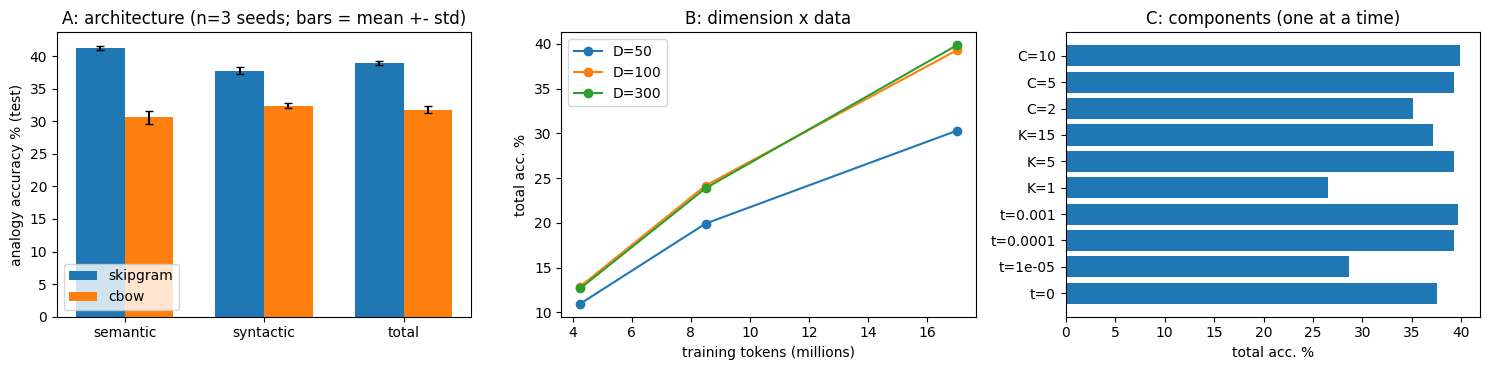

In [13]:
os.makedirs("figures", exist_ok=True)
df = pd.DataFrame(list(_load().values()))
assert len(df) > 0, "results file is empty: run Section 6 (Experiments A, B, C) first"
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

# (a) Experiment A: architecture
a = df[df.tag == "A"].groupby("arch")[["sem", "syn", "total"]].agg(["mean", "std"]).fillna(0)
archs = [r for r in ["skipgram", "cbow"] if r in a.index]; x = np.arange(3); w = 0.35
n_seeds = df[df.tag == "A"].groupby("arch").size().min()      # error bars are drawn ONLY when they are real (>= 2 seeds)
for i, arch in enumerate(archs):
    ax[0].bar(x + (i - (len(archs) - 1) / 2) * w, [a.loc[arch, (m, "mean")] for m in ["sem", "syn", "total"]], w,
              yerr=[a.loc[arch, (m, "std")] for m in ["sem", "syn", "total"]] if n_seeds > 1 else None, capsize=3, label=arch)
ax[0].set_xticks(x); ax[0].set_xticklabels(["semantic", "syntactic", "total"]); ax[0].set_ylabel("analogy accuracy % (test)")
ax[0].set_title(f"A: architecture (n={n_seeds} seed{'s' if n_seeds > 1 else ''}; bars = mean" + (" +- std)" if n_seeds > 1 else ")")); ax[0].legend()

# (b) Experiment B: dimension x data
same = (df.arch == "skipgram") & (df.seed == 0) & (df.C == BASE["C"]) & (df.K == BASE["K"]) & (df.t == BASE["t"]) & (df.epochs == BASE["epochs"])
b = df[same]
for d_ in sorted(b.dim.unique()):
    s = b[b.dim == d_].sort_values("frac"); ax[1].plot(s.frac * 17.0, s.total, "o-", label=f"D={d_}")
ax[1].set_xlabel("training tokens (millions)"); ax[1].set_ylabel("total acc. %"); ax[1].set_title("B: dimension x data"); ax[1].legend()

# (c) Experiment C: base configuration is added to every group as the reference point
base_rows = df[same & (df.dim == BASE["dim"]) & (df.frac == 1.0)].head(1)
labels, vals = [], []
for tag, col in [("C-subsample", "t"), ("C-negatives", "K"), ("C-window", "C")]:
    s = pd.concat([df[df.tag == tag], base_rows]).drop_duplicates(subset=[col]).sort_values(col)
    for _, r in s.iterrows(): labels.append(f"{col}={float(r[col]):g}"); vals.append(float(r["total"]))
ax[2].barh(labels, vals); ax[2].set_xlabel("total acc. %"); ax[2].set_title("C: components (one at a time)")
plt.tight_layout(); plt.savefig("figures/ablations.png", dpi=200); plt.show()

## 8. Qualitative analysis (words chosen *before* looking at results, to avoid cherry-picking)

In [14]:
E = load_embedding("skipgram"); En = F.normalize(E, dim=1)      # provenance-checked, never silently re-trained

def neighbours(w, k=8):
    s = En @ En[stoi[w]]; s[stoi[w]] = -1
    return [itos[i] for i in s.topk(k).indices.tolist()]
for w in ["france", "king", "computer", "big", "quickly", "january"]:
    if w in stoi: print(f"{w:10s} ->", neighbours(w))

def analogy(a, b, c, k=3):
    x = En[stoi[b]] - En[stoi[a]] + En[stoi[c]]; s = En[:VOCAB_EVAL] @ F.normalize(x, dim=0)
    for w in (a, b, c): s[stoi[w]] = -1
    return [itos[i] for i in s.topk(k).indices.tolist()]
print()
for q in [("france", "paris", "italy"), ("big", "bigger", "small"), ("man", "woman", "king"),
          ("walk", "walking", "swim"), ("good", "better", "bad")]:
    if all(w in stoi and stoi[w] < VOCAB_EVAL for w in q): print(f"{q[0]}:{q[1]} :: {q[2]}:?  ->", analogy(*q))

loaded emb_skipgram_full.pt: config verified, test accuracy re-computed = 39.29% (matches the stored value)
france     -> ['belgium', 'spain', 'italy', 'french', 'luxembourg', 'gaulle', 'nantes', 'napol']
king       -> ['throne', 'bertrada', 'kings', 'vii', 'son', 'jehoahaz', 'weds', 'athaliah']
computer   -> ['computers', 'hardware', 'computing', 'configuring', 'reconfigurable', 'machines', 'software', 'graphics']
big        -> ['bang', 'crunch', 'endemol', 'reheating', 'lebowski', 'muff', 'meshes', 'hoardings']
quickly    -> ['soon', 'slowly', 'rapidly', 'eventually', 'when', 'once', 'finally', 'gradually']
january    -> ['february', 'december', 'november', 'october', 'march', 'june', 'september', 'july']

france:paris :: italy:?  -> ['venice', 'turin', 'bologna']
big:bigger :: small:?  -> ['larger', 'smaller', 'large']
man:woman :: king:?  -> ['throne', 'queen', 'consort']
walk:walking :: swim:?  -> ['gallop', 'spotting', 'hiking']
good:better :: bad:?  -> ['worse', 'faster', 'would

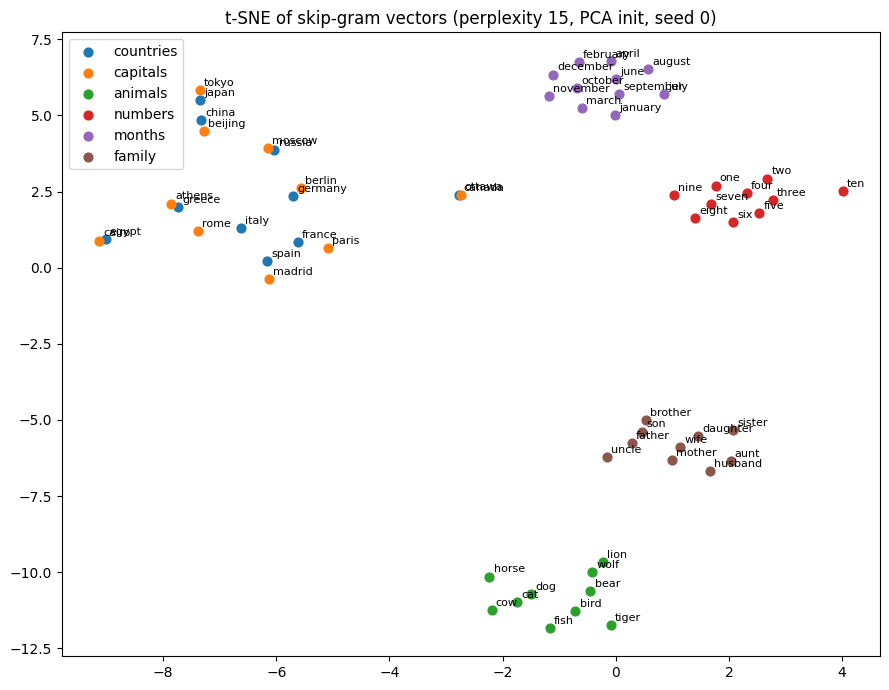

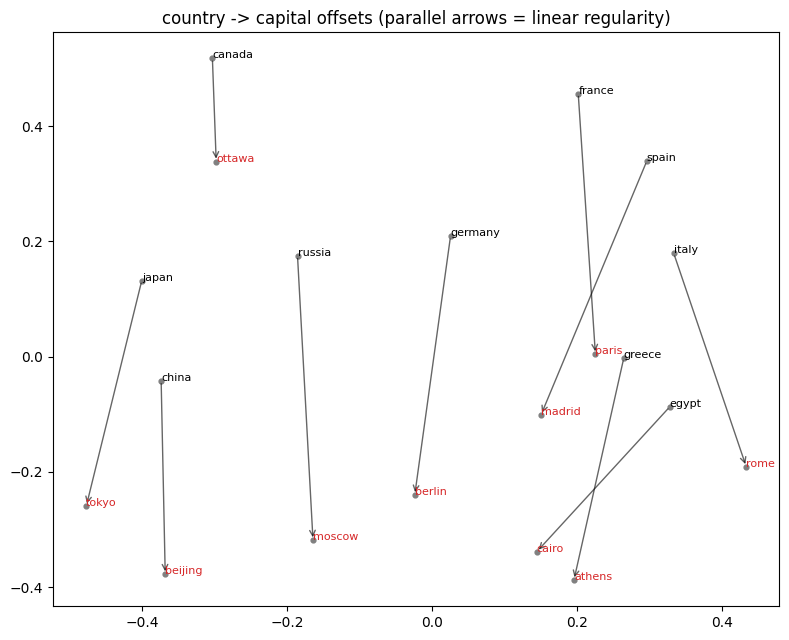

In [15]:
# ---- t-SNE of pre-declared word groups ----
# Explicit, hand-verified country -> capital pairs (a positional zip() of two separate lists mis-paired India/Egypt earlier)
CAPITAL_PAIRS = [("france", "paris"), ("germany", "berlin"), ("italy", "rome"), ("spain", "madrid"), ("greece", "athens"),
                 ("russia", "moscow"), ("china", "beijing"), ("japan", "tokyo"), ("egypt", "cairo"), ("canada", "ottawa")]
GROUPS = {
 "countries": [c for c, _ in CAPITAL_PAIRS],
 "capitals":  [k for _, k in CAPITAL_PAIRS],
 "animals":   "dog cat horse cow bird fish lion tiger wolf bear".split(),
 "numbers":   "one two three four five six seven eight nine ten".split(),
 "months":    "january february march april june july august september october november december".split(),
 "family":    "father mother brother sister son daughter uncle aunt husband wife".split(),
}
from sklearn.manifold import TSNE
words, cats = [], []
for g, ws in GROUPS.items():
    for w in ws:
        if w in stoi and stoi[w] < VOCAB_EVAL: words.append(w); cats.append(g)
X = En[[stoi[w] for w in words]].cpu().numpy()
Z = TSNE(n_components=2, perplexity=min(15, len(words) - 1), init="pca", random_state=0).fit_transform(X)
plt.figure(figsize=(9, 7))
for g in GROUPS:
    m = [i for i, c in enumerate(cats) if c == g]; plt.scatter(Z[m, 0], Z[m, 1], label=g, s=40)
for i, w in enumerate(words): plt.annotate(w, Z[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.legend(); plt.title("t-SNE of skip-gram vectors (perplexity 15, PCA init, seed 0)"); plt.tight_layout()
plt.savefig("figures/tsne.png", dpi=200); plt.show()

# ---- PCA view of the country -> capital offset (linear regularity) ----
from sklearn.decomposition import PCA
pairs = [(c, k) for c, k in CAPITAL_PAIRS if c in stoi and k in stoi and stoi[c] < VOCAB_EVAL and stoi[k] < VOCAB_EVAL]
P = PCA(2).fit_transform(En[[stoi[w] for p in pairs for w in p]].cpu().numpy())
plt.figure(figsize=(8, 6.5))
plt.scatter(P[:, 0], P[:, 1], s=12, color="gray")      # makes matplotlib auto-scale the axes to the data
for i, (c, k) in enumerate(pairs):
    plt.annotate("", P[2*i+1], P[2*i], arrowprops=dict(arrowstyle="->", alpha=.6))
    plt.text(*P[2*i], c, fontsize=8); plt.text(*P[2*i+1], k, fontsize=8, color="C3")
plt.title("country -> capital offsets (parallel arrows = linear regularity)"); plt.tight_layout()
plt.savefig("figures/pca_offsets.png", dpi=200); plt.show()

### 8.1 Failure analysis (required in the report): which question types fail and what the model predicts instead

In [16]:
det = analogy_eval(E, return_details=True)
rows = [(ANALOGIES[i][0], c, not IS_DEV[i]) for i, c in zip(det["keep"], det["correct"])]
cat = pd.DataFrame(rows, columns=["category", "correct", "test"]); cat = cat[cat.test]
tab = cat.groupby("category").correct.agg(["mean", "count"]); tab["mean"] *= 100
total_per_cat = pd.Series([q[0] for i, q in enumerate(ANALOGIES) if not IS_DEV[i]]).value_counts()
tab["coverage_%"] = (100 * tab["count"] / total_per_cat).round(1); tab["mean"] = tab["mean"].round(1)
display(tab.sort_values("mean"))

wrong = [(ANALOGIES[i], itos[p]) for i, c, p in zip(det["keep"], det["correct"], det["preds"]) if not c and not IS_DEV[i]]
random.Random(0).shuffle(wrong)
print("\nrandom wrong test answers (seed 0):")
for q, p in wrong[:15]: print(f"  {q[1]}:{q[2]} :: {q[3]}:?   gold={q[4]:<14s} predicted={p}")

,mean,count,coverage_%
category,,,
gram2-opposite,5.9,237,36.6
gram1-adjective-to-adverb,13.6,619,77.4
gram5-present-participle,18.2,785,94.0
currency,20.4,216,31.7
gram4-superlative,23.2,409,45.0
gram9-plural-verbs,23.8,526,74.2
city-in-state,26.1,1262,64.3
gram7-past-tense,26.4,1071,85.8
gram3-comparative,41.0,993,94.1



random wrong test answers (seed 0):
  low:lowest :: big:?   gold=biggest        predicted=bang
  efficient:efficiently :: precise:?   gold=precisely      predicted=exact
  computer:computers :: pig:?   gold=pigs           predicted=chickens
  amazing:amazingly :: usual:?   gold=usually        predicted=lower
  nephew:niece :: husband:?   gold=wife           predicted=her
  work:works :: talk:?   gold=talks          predicted=realaudio
  warsaw:poland :: amman:?   gold=jordan         predicted=governorates
  short:shorter :: young:?   gold=younger        predicted=skirts
  easy:easiest :: good:?   gold=best           predicted=bad
  miami:florida :: pittsburgh:?   gold=pennsylvania   predicted=maryland
  monkey:monkeys :: cow:?   gold=cows           predicted=disease
  lexington:kentucky :: cincinnati:?   gold=ohio           predicted=cleveland
  baltimore:maryland :: minneapolis:?   gold=minnesota      predicted=illinois
  fast:fastest :: wide:?   gold=widest         predicted=range
 

## 9. Optional external sanity check (clearly *not* my implementation)
If my numbers are far below a mature library trained on identical data with identical hyper-parameters, I probably have a bug. If they are close, the implementation is validated. This is a **reference run only** and must be labelled as such in the report.

In [17]:
from gensim.models import Word2Vec as GensimW2V
sents = [tokens[i:i + 1000] for i in range(0, len(tokens), 1000)]
rows = []
for sg, name in [(1, "skipgram"), (0, "cbow")]:
    t0 = time.time()
    gm = GensimW2V(sents, vector_size=BASE["dim"], window=BASE["C"], negative=BASE["K"], sample=BASE["t"],
                   min_count=BASE["min_count"], sg=sg, epochs=BASE["epochs"], seed=0, workers=2)
    Eg = torch.tensor(np.stack([gm.wv[w] for w in itos]))
    r = {**analogy_eval(Eg), **similarity_eval(Eg)}
    print(f"gensim reference {name:8s} | sem {r['sem']:.1f} syn {r['syn']:.1f} tot {r['total']:.1f} | WS353 {r['ws353_rho']:.3f} | {time.time()-t0:.0f}s")

gensim reference skipgram | sem 21.0 syn 34.3 tot 29.8 | WS353 0.648 | 196s
gensim reference cbow     | sem 11.8 syn 21.4 tot 18.2 | WS353 0.575 | 60s


## 10. Final results table, paper comparison, export
**Paper numbers for context** (different corpus and scale, so compare *trends*, not absolute values):

| Paper setting | Semantic | Syntactic | Total |
|---|---|---|---|
| Table 5: CBOW, 300-d, 783M words, 3 ep. | 15.5 | 53.1 | 36.1 |
| Table 5: Skip-gram, 300-d, 783M words, 3 ep. | 50.0 | 55.9 | 53.3 |
| Table 3: CBOW 640-d (320M words) | 24 | 64 | — |
| Table 3: Skip-gram 640-d (320M words) | 55 | 59 | — |

**Expected differences to explain in the report:** (i) text8 has 17 M tokens (≈46× fewer than 783 M), so the semantic questions (capitals, currencies, US states) are poorly covered; (ii) the paper uses hierarchical softmax and SGD, we use negative sampling and Adam; (iii) the paper's eval vocabulary is the full 1M words in Table 4, 30k in Table 2.

In [18]:
df = pd.DataFrame(list(_load().values()))
cols = ["tag", "arch", "dim", "C", "K", "t", "frac", "epochs", "seed", "sem", "syn", "total", "dev_total", "coverage", "ws353_rho", "time_s"]
ROUND = {"sem": 2, "syn": 2, "total": 2, "dev_total": 2, "coverage": 2, "ws353_rho": 3, "time_s": 1}   # never round hyper-parameters (t = 1e-4 would become 0.0)
df[cols].round(ROUND).to_csv("results.csv", index=False)
display(df[cols].round(ROUND))
!zip -qr w2v_outputs.zip figures results.csv {RESULTS_FILE} lr_choice.json emb_*.pt && echo "zipped -> download w2v_outputs.zip from the Files panel"

,tag,arch,dim,C,K,t,frac,epochs,seed,sem,syn,total,dev_total,coverage,ws353_rho,time_s
0,A,skipgram,100,5,5,0.00010,1.00,3,0,41.19,38.33,39.29,41.62,62.77,0.688,90.8
1,A,skipgram,100,5,5,0.00010,1.00,3,1,41.01,37.52,38.69,39.52,62.77,0.695,91.1
2,A,skipgram,100,5,5,0.00010,1.00,3,2,41.59,37.39,38.80,39.76,62.77,0.699,90.9
3,A,cbow,100,5,5,0.00010,1.00,3,0,30.01,32.18,31.45,30.59,62.77,0.711,74.9
4,A,cbow,100,5,5,0.00010,1.00,3,1,31.68,32.87,32.47,33.33,62.77,0.692,74.1
5,A,cbow,100,5,5,0.00010,1.00,3,2,30.07,32.15,31.45,31.84,62.77,0.706,74.8
6,A-extra,cbow,100,5,5,0.00010,1.00,9,0,38.49,38.15,38.26,39.19,62.77,0.693,224.8
7,B,skipgram,50,5,5,0.00010,0.25,3,0,9.36,11.75,10.95,10.18,62.77,0.557,18.7
8,B,skipgram,50,5,5,0.00010,0.50,3,0,16.07,21.87,19.92,19.84,62.77,0.654,37.2
9,B,skipgram,50,5,5,0.00010,1.00,3,0,28.01,31.46,30.30,30.87,62.77,0.672,74.1


zipped -> download w2v_outputs.zip from the Files panel
